# Final Model

## Road Accident Risk Prediction and Safety Prioritization

This notebook implements the final predictive modeling workflow for the
road-accident risk screening tool.

The final workflow uses:

- Multiple Linear Regression to estimate continuous accident risk.
- Logistic Regression to estimate the probability that an observation
  belongs to the high-risk group.
- A classification probability threshold of 0.40 for the final
  high-risk screening decision.

The 0.40 classification threshold was selected during model development
because it produced the highest F1 score among the evaluated thresholds
while increasing recall compared with the default 0.50 threshold.

This notebook focuses only on the final reproducible modeling workflow.
Exploratory analysis and model-development experiments are documented in
the earlier project notebooks.

## 1. Setup and Imports

This section imports the libraries required for data preparation,
model training, evaluation, and artifact storage.

In [28]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

In [29]:
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts"

TRAIN_PATH = DATA_DIR / "train.csv"

ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Project root:", PROJECT_ROOT)
print("Training data:", TRAIN_PATH)
print("Artifact directory:", ARTIFACT_DIR)

Project root: c:\Users\ngoho\OneDrive\Desktop\UOP\Fall 2026\MSBA 265\road-accident-risk-prediction
Training data: c:\Users\ngoho\OneDrive\Desktop\UOP\Fall 2026\MSBA 265\road-accident-risk-prediction\data\train.csv
Artifact directory: c:\Users\ngoho\OneDrive\Desktop\UOP\Fall 2026\MSBA 265\road-accident-risk-prediction\artifacts


In [30]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

TABLE_DIR = PROJECT_ROOT / "reports" / "tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)

FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print(TABLE_DIR)
print(FIGURE_DIR)

c:\Users\ngoho\OneDrive\Desktop\UOP\Fall 2026\MSBA 265\road-accident-risk-prediction\reports\tables
c:\Users\ngoho\OneDrive\Desktop\UOP\Fall 2026\MSBA 265\road-accident-risk-prediction\reports\figures


## 2. Load and Split Data

The labeled training dataset is loaded and divided into training and
validation subsets.

The `id` column is excluded because it is an identifier rather than a
predictive feature.

A fixed random state is used to make the split reproducible.

In [31]:
TARGET = "accident_risk"

TEST_SIZE = 0.20
RANDOM_STATE = 42

df = pd.read_csv(TRAIN_PATH)

X = df.drop(
    columns=["id", TARGET]
)

y = df[TARGET]

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

print("Full dataset:", df.shape)
print("Training predictors:", X_train.shape)
print("Validation predictors:", X_val.shape)

print(
    "Training target mean:",
    round(y_train.mean(), 6)
)

print(
    "Validation target mean:",
    round(y_val.mean(), 6)
)

Full dataset: (517754, 14)
Training predictors: (414203, 12)
Validation predictors: (103551, 12)
Training target mean: 0.352605
Validation target mean: 0.351466


## 3. Final Feature Configuration

The final models use the 12 predictive variables identified during model
development.

Categorical variables are one-hot encoded. Boolean variables are
converted to integer values, while numeric variables are passed through
without scaling.

In [32]:
numeric_features = [
    "num_lanes",
    "curvature",
    "speed_limit",
    "num_reported_accidents"
]

categorical_features = [
    "road_type",
    "lighting",
    "weather",
    "time_of_day"
]

boolean_features = [
    "road_signs_present",
    "public_road",
    "holiday",
    "school_season"
]

In [33]:
for column in boolean_features:

    X_train[column] = (
        X_train[column]
        .astype(int)
    )

    X_val[column] = (
        X_val[column]
        .astype(int)
    )

In [34]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ],
    remainder="passthrough"
)

In [35]:
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Boolean features:", len(boolean_features))
print(
    "Total original predictors:",
    len(
        numeric_features
        + categorical_features
        + boolean_features
    )
)

Numeric features: 4
Categorical features: 4
Boolean features: 4
Total original predictors: 12


## 4. Final Multiple Linear Regression Model

Multiple Linear Regression is used to estimate the continuous
`accident_risk` target.

The preprocessing workflow and regression model are combined in a single
pipeline to ensure that the same transformations are applied consistently
during training and prediction.

Model performance is evaluated on the held-out validation set using
RMSE, MAE, and R².

In [36]:
regression_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "regressor",
            LinearRegression()
        )
    ]
)

regression_pipeline.fit(
    X_train,
    y_train
);

In [37]:
regression_predictions = (
    regression_pipeline.predict(X_val)
)

In [38]:
regression_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        regression_predictions
    )
)

regression_mae = mean_absolute_error(
    y_val,
    regression_predictions
)

regression_r2 = r2_score(
    y_val,
    regression_predictions
)

print(
    "Validation RMSE:",
    round(regression_rmse, 6)
)

print(
    "Validation MAE:",
    round(regression_mae, 6)
)

print(
    "Validation R²:",
    round(regression_r2, 6)
)

Validation RMSE: 0.073531
Validation MAE: 0.058312
Validation R²: 0.804188


In [39]:
baseline_predictions = np.full(
    len(y_val),
    y_train.mean()
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        baseline_predictions
    )
)

print(
    "Baseline RMSE:",
    round(baseline_rmse, 6)
)

print(
    "Regression RMSE:",
    round(regression_rmse, 6)
)

Baseline RMSE: 0.166173
Regression RMSE: 0.073531


### Regression Result

The final regression model achieved a validation R² of approximately
0.804, indicating that the model explains about 80.4% of the variation
in accident risk.

Its validation RMSE was approximately 0.0735, substantially lower than
the mean-prediction baseline RMSE of approximately 0.1662.

These results support using the regression model as the continuous-risk
component of the final screening workflow.

## 5. Final Logistic Regression Classification Model

Logistic Regression is used to estimate the probability that each road
condition belongs to the high-risk group.

The high-risk target is defined using the 75th percentile of the
training-set `accident_risk` distribution. Using the training data only
to define this threshold prevents the validation target from influencing
the classification rule.

The final classification model uses the same preprocessing workflow as
the regression model.

In [40]:
high_risk_threshold = y_train.quantile(0.75)

y_train_high = (
    y_train >= high_risk_threshold
).astype(int)

y_val_high = (
    y_val >= high_risk_threshold
).astype(int)

print(
    "High-risk target threshold:",
    round(high_risk_threshold, 4)
)

print(
    "Training high-risk rate:",
    round(y_train_high.mean(), 4)
)

print(
    "Validation high-risk rate:",
    round(y_val_high.mean(), 4)
)

High-risk target threshold: 0.46
Training high-risk rate: 0.2531
Validation high-risk rate: 0.2499


In [41]:
classification_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000
            )
        )
    ]
)

classification_pipeline.fit(
    X_train,
    y_train_high
);

In [42]:
high_risk_probabilities = (
    classification_pipeline.predict_proba(
        X_val
    )[:, 1]
)

print(
    "Number of validation probabilities:",
    len(high_risk_probabilities)
)

print(
    "Minimum probability:",
    high_risk_probabilities.min()
)

print(
    "Maximum probability:",
    high_risk_probabilities.max()
)

Number of validation probabilities: 103551
Minimum probability: 2.2318691379434112e-06
Maximum probability: 0.9999698639456046


In [43]:
CLASSIFICATION_THRESHOLD = 0.40

final_classification_predictions = (
    high_risk_probabilities
    >= CLASSIFICATION_THRESHOLD
).astype(int)

In [44]:
classification_accuracy = accuracy_score(
    y_val_high,
    final_classification_predictions
)

classification_precision = precision_score(
    y_val_high,
    final_classification_predictions
)

classification_recall = recall_score(
    y_val_high,
    final_classification_predictions
)

classification_f1 = f1_score(
    y_val_high,
    final_classification_predictions
)

classification_cm = confusion_matrix(
    y_val_high,
    final_classification_predictions
)

print(
    "Classification threshold:",
    CLASSIFICATION_THRESHOLD
)

print(
    "Accuracy:",
    round(classification_accuracy, 6)
)

print(
    "Precision:",
    round(classification_precision, 6)
)

print(
    "Recall:",
    round(classification_recall, 6)
)

print(
    "F1:",
    round(classification_f1, 6)
)

print("Confusion Matrix:")
print(classification_cm)

Classification threshold: 0.4
Accuracy: 0.892459
Precision: 0.773209
Recall: 0.806021
F1: 0.789274
Confusion Matrix:
[[71560  6117]
 [ 5019 20855]]


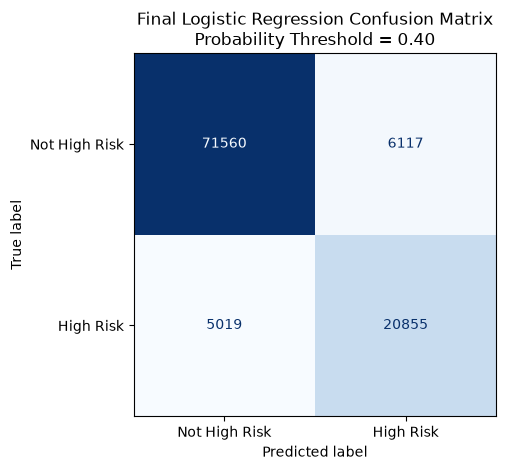

In [45]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=classification_cm,
    display_labels=["Not High Risk", "High Risk"]
)

disp.plot(
    cmap="Blues",
    colorbar=False
)

plt.title(
    "Final Logistic Regression Confusion Matrix\n"
    "Probability Threshold = 0.40"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "09_final_classification_confusion_matrix_040.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Classification Result

Using the final probability threshold of 0.40, the Logistic Regression
model achieved approximately 89.2% accuracy, 77.3% precision, 80.6%
recall, and an F1 score of 78.9%.

The model correctly identified about 80.6% of the actual high-risk
validation observations. Compared with the default 0.50 probability
threshold, the optimized threshold reduces false negatives and improves
recall while maintaining a strong overall balance between precision and
recall.

This makes the classification model suitable for the screening objective,
where identifying potentially high-risk observations is especially
important.

## 6. Final Model Evaluation

This section summarizes the performance of the two final predictive
components used in the road-safety screening workflow.

The Multiple Linear Regression model estimates continuous accident risk,
while the Logistic Regression model identifies observations that should
be flagged as high risk using the selected probability threshold of 0.40.

In [46]:
final_results = pd.DataFrame({
    "Model": [
        "Multiple Linear Regression",
        "Logistic Regression"
    ],
    "Metric 1": [
        f"RMSE = {regression_rmse:.4f}",
        f"Accuracy = {classification_accuracy:.4f}"
    ],
    "Metric 2": [
        f"MAE = {regression_mae:.4f}",
        f"Precision = {classification_precision:.4f}"
    ],
    "Metric 3": [
        f"R² = {regression_r2:.4f}",
        f"Recall = {classification_recall:.4f}"
    ],
    "Metric 4": [
        "",
        f"F1 = {classification_f1:.4f}"
    ]
})

final_results

,Model,Metric 1,Metric 2,Metric 3,Metric 4
0,Multiple Linear Regression,RMSE = 0.0735,MAE = 0.0583,R² = 0.8042,
1,Logistic Regression,Accuracy = 0.8925,Precision = 0.7732,Recall = 0.8060,F1 = 0.7893


In [47]:
final_results.to_csv(
    TABLE_DIR / "10_final_model_results.csv",
    index=False
)

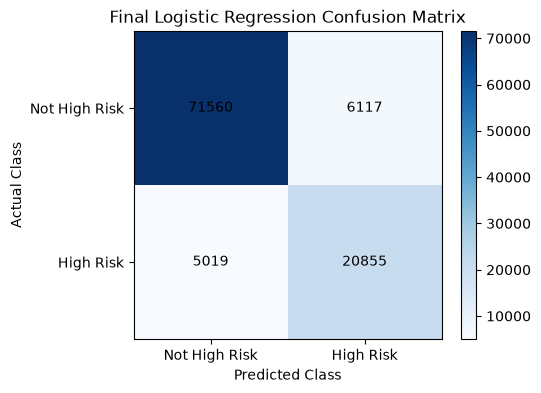

In [48]:
plt.figure(figsize=(5, 4))

plt.imshow(
    classification_cm,
    cmap="Blues"
)

plt.title(
    "Final Logistic Regression Confusion Matrix"
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(
    [0, 1],
    ["Not High Risk", "High Risk"]
)

plt.yticks(
    [0, 1],
    ["Not High Risk", "High Risk"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            classification_cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.show()

### Final Evaluation Summary

The Multiple Linear Regression model provides a strong continuous-risk
estimate, explaining approximately 80.4% of the variation in accident
risk.

The final Logistic Regression model, using the optimized probability
threshold of 0.40, identifies approximately 80.6% of actual high-risk
observations while maintaining approximately 77.3% precision.

Together, the two models provide complementary outputs for the screening
tool: a continuous accident-risk estimate and a high-risk classification
for prioritization.

## 7. Save Final Model Artifacts

The final regression and classification pipelines are saved so they can
be reused by the application without retraining the models.

Classification metadata is also stored separately to preserve the
high-risk target definition and the selected classification probability
threshold.

In [49]:
regression_artifact_path = (
    ARTIFACT_DIR / "regression_pipeline.joblib"
)

classification_artifact_path = (
    ARTIFACT_DIR / "classification_pipeline.joblib"
)

metadata_artifact_path = (
    ARTIFACT_DIR / "classification_metadata.joblib"
)

In [50]:
classification_metadata = {
    "high_risk_threshold": float(
        high_risk_threshold
    ),
    "high_risk_definition": (
        "accident_risk >= training-set 75th percentile"
    ),
    "classification_probability_threshold": float(
        CLASSIFICATION_THRESHOLD
    )
}

classification_metadata

{'high_risk_threshold': 0.46,
 'high_risk_definition': 'accident_risk >= training-set 75th percentile',
 'classification_probability_threshold': 0.4}

In [51]:
joblib.dump(
    regression_pipeline,
    regression_artifact_path
)

joblib.dump(
    classification_pipeline,
    classification_artifact_path
)

joblib.dump(
    classification_metadata,
    metadata_artifact_path
)

print(
    "Saved:",
    regression_artifact_path.name
)

print(
    "Saved:",
    classification_artifact_path.name
)

print(
    "Saved:",
    metadata_artifact_path.name
)

Saved: regression_pipeline.joblib
Saved: classification_pipeline.joblib
Saved: classification_metadata.joblib


In [52]:
print(
    "Regression artifact exists:",
    regression_artifact_path.exists()
)

print(
    "Classification artifact exists:",
    classification_artifact_path.exists()
)

print(
    "Metadata artifact exists:",
    metadata_artifact_path.exists()
)

Regression artifact exists: True
Classification artifact exists: True
Metadata artifact exists: True


## 8. Reload and Verify Final Artifacts

The saved model artifacts are reloaded to verify that they reproduce the
same predictions as the models used in this notebook.

This step confirms that the stored pipelines and metadata can be used
reliably by the final application.

In [53]:
loaded_regression_pipeline = joblib.load(
    regression_artifact_path
)

loaded_classification_pipeline = joblib.load(
    classification_artifact_path
)

loaded_classification_metadata = joblib.load(
    metadata_artifact_path
)

In [54]:
loaded_regression_predictions = (
    loaded_regression_pipeline.predict(X_val)
)

regression_predictions_match = np.allclose(
    regression_predictions,
    loaded_regression_predictions
)

print(
    "Regression predictions match:",
    regression_predictions_match
)

Regression predictions match: True


In [55]:
loaded_classification_probabilities = (
    loaded_classification_pipeline.predict_proba(
        X_val
    )[:, 1]
)

classification_probabilities_match = np.allclose(
    high_risk_probabilities,
    loaded_classification_probabilities
)

print(
    "Classification probabilities match:",
    classification_probabilities_match
)

Classification probabilities match: True


In [56]:
loaded_probability_threshold = (
    loaded_classification_metadata[
        "classification_probability_threshold"
    ]
)

loaded_high_risk_threshold = (
    loaded_classification_metadata[
        "high_risk_threshold"
    ]
)

print(
    "Loaded classification threshold:",
    loaded_probability_threshold
)

print(
    "Loaded high-risk target threshold:",
    loaded_high_risk_threshold
)

Loaded classification threshold: 0.4
Loaded high-risk target threshold: 0.46


In [57]:
loaded_classification_predictions = (
    loaded_classification_probabilities
    >= loaded_probability_threshold
).astype(int)

classification_predictions_match = np.array_equal(
    final_classification_predictions,
    loaded_classification_predictions
)

print(
    "Classification predictions match:",
    classification_predictions_match
)

Classification predictions match: True


### Artifact Verification Result

All saved artifacts reproduced the same regression predictions,
classification probabilities, and final high-risk classifications as
the models used during evaluation.

The stored classification metadata also preserved the high-risk target
threshold of 0.46 and the final classification probability threshold of
0.40.

This confirms that the saved artifacts are ready for use in the final
screening application.

## 9. Final Model Summary

The final road-accident risk screening workflow combines two complementary predictive models.

The Multiple Linear Regression model estimates continuous accident risk and achieved a validation RMSE of approximately 0.0735 and an R² of approximately 0.804.

The Logistic Regression model identifies high-risk road conditions. The high-risk target was defined using the training-set 75th percentile of `accident_risk`, corresponding to a threshold of 0.46.

For final classification decisions, a probability threshold of 0.40 was used. This threshold produced approximately 89.2% accuracy, 77.3% precision, 80.6% recall, and an F1 score of 78.9% on the validation set.

The final artifacts were saved and successfully reloaded, reproducing the same predictions as the models used during evaluation.

Together, the regression and classification models support the project objective by providing both a continuous accident-risk estimate and a high-risk screening flag for transportation safety prioritization.

This workflow is intended as a proof-of-concept decision-support tool and should not replace professional transportation safety or engineering analysis.